# Read and plot the original source

Source measurements for `Fig_1A`, with the same selection, grouping and plot representations as `read_atst.ipynb`. Matplotlib reads and plots the original source directly.


In [1]:
import math
import matplotlib.pyplot as plt
import pandas as pd
from openpyxl import load_workbook

readout_id = "Fig_1A"
rows, curves = [], []

sheet = load_workbook(
    "read_shared_data/sources/42003_2024_7269_MOESM4_ESM.xlsx",
    read_only=True,
    data_only=True,
)["Figure 1"]
time = [row[0].value for row in sheet["A3:A11"]]
for phage, first in [("", 2), ("VAC1", 10), ("VAC3", 18)]:
    for replicate, column in enumerate(range(first, first + 8), 1):
        rows.append(
            {
                "type": "phage_exposed" if phage else "uninfected_control",
                "phage_id": phage,
                "replicate": str(replicate),
            }
        )
        curves.append(
            pd.Series([sheet.cell(r, column).value for r in range(3, 12)], index=time)
        )

layout = pd.DataFrame(rows)
layout["curve_id"] = [f"curve_{i}" for i in range(1, len(rows) + 1)]
readings = pd.concat(curves, axis=1).sort_index()
readings.columns = layout["curve_id"]
readings = readings.rename_axis("Time").reset_index()


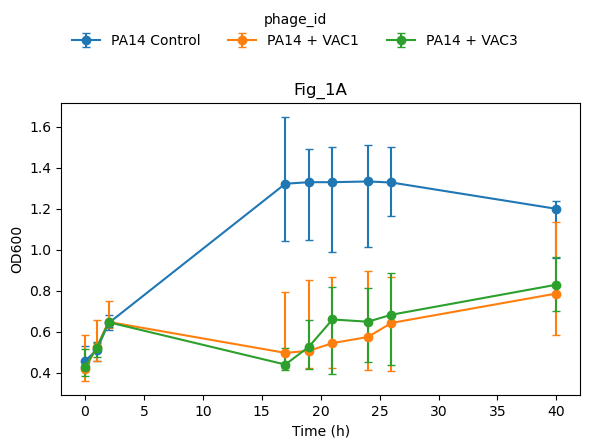

In [2]:
plot_layout = layout
panels = [(None, plot_layout)]
ncols = min(2, len(panels))
nrows = math.ceil(len(panels) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows), squeeze=False)
palette = plt.rcParams["axes.prop_cycle"].by_key()["color"]
condition_colors = {}

for ax, (panel, panel_layout) in zip(axes.flat, panels):
    for condition, group in panel_layout.groupby('phage_id', sort=False):
        if condition not in condition_colors:
            condition_colors[condition] = palette[len(condition_colors) % len(palette)]
        color = condition_colors[condition]
        label = {'': 'PA14 Control', 'VAC1': 'PA14 + VAC1', 'VAC3': 'PA14 + VAC3'}[str(condition)]
        values = readings[group["curve_id"]]
        median = values.median(axis=1)
        minimum = values.min(axis=1)
        maximum = values.max(axis=1)
        ax.errorbar(readings["Time"], median,
                    yerr=[median - minimum, maximum - median],
                    fmt='o-', capsize=3, color=color, label=label)
    ax.set_xlabel("Time (h)")
    ax.set_ylabel("OD600")
    ax.set_title(readout_id)

for ax in list(axes.flat)[len(panels):]:
    fig.delaxes(ax)
legend_entries = {}
for ax in fig.axes:
    handles, labels = ax.get_legend_handles_labels()
    for handle, label in zip(handles, labels):
        legend_entries.setdefault(label, handle)
ncols = 1 if max(map(len, legend_entries)) > 40 else min(4, len(legend_entries))
fig.legend(list(legend_entries.values()), list(legend_entries),
           title='phage_id', loc="upper center", ncol=ncols, frameon=False)
legend_height = (0.25 * math.ceil(len(legend_entries) / ncols) + 0.4) / fig.get_figheight()
fig.tight_layout(rect=(0, 0, 1, 1 - legend_height))
plt.show()
